# Lab 5: warstwy splotowe (kod)
Ten notebook zawiera **tylko kod i eksperymenty**. Sprawozdanie jest w osobnym pliku `REPORT.md`; notebook zapisuje wykresy i tabele do `figures/` i `results/`.

**Przed uruchomieniem:** przygotuj **własne zdjęcie** (inne niż zdjęcie z ćwiczenia). Kolor nie szkodzi, notebook sam zamieni je na skalę szarości. W komórce konfiguracji wpisz nazwę pliku albo wgraj go, gdy notebook o to poprosi (Colab). Potem Runtime → Run all.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FIG_DIR, RES_DIR = Path("figures"), Path("results")
for d in (FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cuda


## 0. Konfiguracja i zdjęcie

In [ ]:
PHOTO_PATH = "moje_zdjecie.jpg"  # nazwa pliku z własnym zdjęciem
MAX_SIDE = 512  # dłuższy bok po zmniejszeniu [px]
CROP_SIZE = 96  # rozmiar kwadratowego fragmentu do porównania rozmyć
CROP = None  # (górny wiersz, lewa kolumna) lub None = wybór automatyczny

In [ ]:
if not Path(PHOTO_PATH).exists():
    try:
        from google.colab import files

        print("Wgraj własne zdjęcie:")
        uploaded = files.upload()
        PHOTO_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Brak pliku {PHOTO_PATH}")
print("Zdjęcie:", PHOTO_PATH)

Wgraj własne zdjęcie:


Saving bird.bmp to bird.bmp
Zdjęcie: bird.bmp


In [ ]:
pil_orig = ImageOps.exif_transpose(
    Image.open(PHOTO_PATH)
)  # zdjęcia z telefonu
pil_gray = pil_orig.convert("L")
scale = MAX_SIDE / max(pil_gray.size)
if scale < 1:
    new_size = (round(pil_gray.width * scale), round(pil_gray.height * scale))
    pil_gray = pil_gray.resize(new_size, Image.Resampling.LANCZOS)
pil_rgb = pil_gray.convert("RGB")  # te same 3 kanały dla ResNet-18

gray = torch.from_numpy(np.array(pil_gray)).float().div(255)
gray = gray.view(1, 1, pil_gray.height, pil_gray.width)  # [1, 1, H, W]
H, W = gray.shape[-2:]
print(f"Oryginał: {pil_orig.size} px | po zmniejszeniu: {W}x{H} px")
print("Zakres wartości:", gray.min().item(), "-", gray.max().item())
pil_gray.save(FIG_DIR / "photo_gray.png")

Oryginał: (512, 512) px | po zmniejszeniu: 512x512 px
Zakres wartości: 0.03529411926865578 - 0.8313725590705872


### Jądra ręczne
Wagi jąder zgodnie ze wstępem teoretycznym. Suma wag: 0 dla jąder wykrywających zmiany (Sobel, Laplacian), 1 dla jąder zachowujących jasność (Sharpen, Box, Gaussian).

In [ ]:
def kernel(rows):
    t = torch.tensor(rows, dtype=torch.float32)
    return t.view(1, 1, *t.shape)  # [C_out, C_in, kH, kW]


sobel_x = kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.transpose(-2, -1)
laplacian8 = kernel([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
sharpen = kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
box3 = torch.ones(1, 1, 3, 3) / 9
box5 = torch.ones(1, 1, 5, 5) / 25
v = torch.tensor([1.0, 4.0, 6.0, 4.0, 1.0])
gauss5 = (torch.outer(v, v) / 256).view(1, 1, 5, 5)

named = {
    "Sobel X": sobel_x,
    "Sobel Y": sobel_y,
    "Laplacian (8 sąsiadów)": laplacian8,
    "Sharpen": sharpen,
    "Box 3x3": box3,
    "Box 5x5": box5,
    "Gaussian 5x5": gauss5,
}
sums = pd.DataFrame(
    {
        "jądro": list(named),
        "rozmiar": [f"{k.shape[-2]}x{k.shape[-1]}" for k in named.values()],
        "suma wag": [round(k.sum().item(), 4) for k in named.values()],
    }
)
sums.to_csv(RES_DIR / "kernel_sums.csv", index=False)
display(sums)

,jądro,rozmiar,suma wag
0,Sobel X,3x3,0.0
1,Sobel Y,3x3,0.0
2,Laplacian (8 sąsiadów),3x3,0.0
3,Sharpen,3x3,1.0
4,Box 3x3,3x3,1.0
5,Box 5x5,5x5,1.0
6,Gaussian 5x5,5x5,1.0


Wybrany fragment: wiersz 416, kolumna 232, rozmiar 96x96


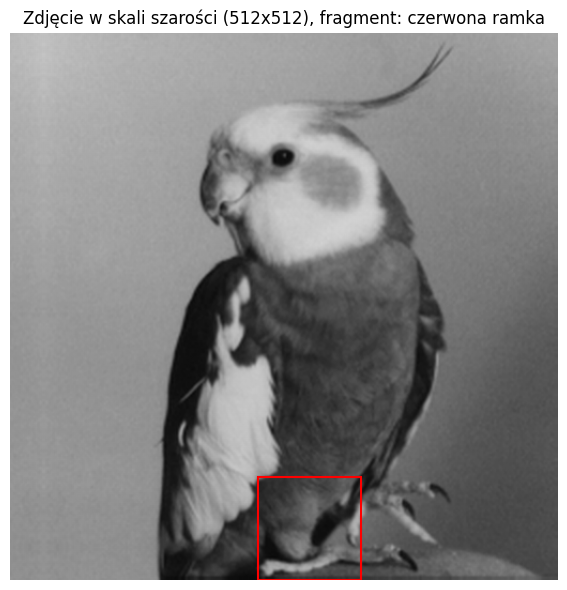

In [ ]:
def sobel_magnitude(img):
    gx_ = F.conv2d(img, sobel_x, padding=1)
    gy_ = F.conv2d(img, sobel_y, padding=1)
    return (gx_.square() + gy_.square()).sqrt()


def auto_crop(img, size, stride=8):
    # okno o największej średniej sile krawędzi (informatywny fragment)
    score = F.avg_pool2d(sobel_magnitude(img), size, stride=stride)[0, 0]
    r, c = np.unravel_index(score.argmax().item(), tuple(score.shape))
    return int(r * stride), int(c * stride)


size = min(CROP_SIZE, H, W)
top, left = auto_crop(gray, size) if CROP is None else CROP
print(f"Wybrany fragment: wiersz {top}, kolumna {left}, rozmiar {size}x{size}")

fig, ax = plt.subplots(figsize=(6, 6 * H / W))
ax.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
ax.add_patch(
    plt.Rectangle(
        (left - 0.5, top - 0.5),
        size,
        size,
        fill=False,
        edgecolor="red",
        lw=1.5,
    )
)
ax.set_title(f"Zdjęcie w skali szarości ({W}x{H}), fragment: czerwona ramka")
ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "photo_and_crop.png", dpi=150)
plt.show()

## 1. Ręczne jądra przez `F.conv2d`
Sobel X/Y, magnituda gradientu, Laplacian, Sharpen i rozmycie Box 5×5 (padding zachowuje rozmiar). Mapy ze znakiem (Sobel, Laplacian) pokazano paletą rozbieżną wyśrodkowaną w zerze.

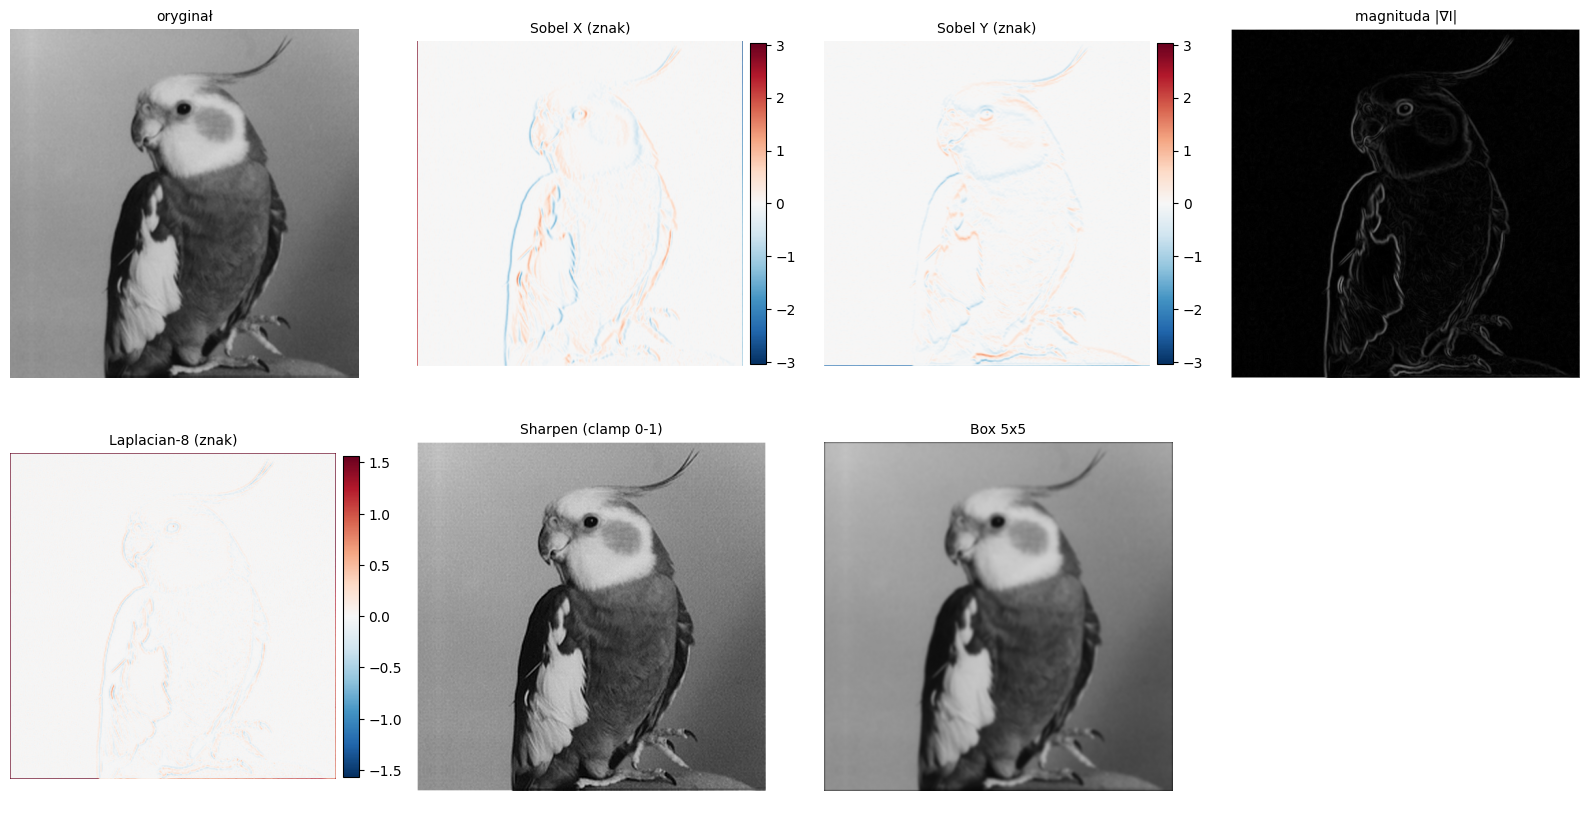

In [ ]:
gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
mag = (gx.square() + gy.square()).sqrt()
lap = F.conv2d(gray, laplacian8, padding=1)
sharp = F.conv2d(gray, sharpen, padding=1).clamp(0, 1)
blur5 = F.conv2d(gray, box5, padding=2)

vmax_s = max(gx.abs().max().item(), gy.abs().max().item())
vmax_l = torch.quantile(lap.abs().flatten(), 0.995).item()
panels = [
    ("oryginał", gray, "gray", (0, 1)),
    ("Sobel X (znak)", gx, "RdBu_r", (-vmax_s, vmax_s)),
    ("Sobel Y (znak)", gy, "RdBu_r", (-vmax_s, vmax_s)),
    ("magnituda |∇I|", mag, "gray", (0, mag.max().item())),
    ("Laplacian-8 (znak)", lap, "RdBu_r", (-vmax_l, vmax_l)),
    ("Sharpen (clamp 0-1)", sharp, "gray", (0, 1)),
    ("Box 5x5", blur5, "gray", (0, 1)),
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8 * H / W + 0.6))
for ax in axes.flat:
    ax.axis("off")
for ax, (title, t, cmap, (lo, hi)) in zip(axes.flat, panels):
    im = ax.imshow(t[0, 0], cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title, fontsize=10)
    if cmap == "RdBu_r":
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "hand_kernels.png", dpi=150)
plt.show()

## 2. Wzór na wymiary wyjścia vs `nn.Conv2d`
`out = ⌊(in + 2p − d(k−1) − 1) / s⌋ + 1`, liczone osobno dla wysokości i szerokości. Oprócz pięciu konfiguracji dla wejścia 32×32 sprawdzamy przypadek z zaokrągleniem w dół (8×8) i niekwadratowe wejście 6×7 z wstępu.

In [ ]:
def out_dim(n, k, s=1, p=0, d=1):
    return (n + 2 * p - d * (k - 1) - 1) // s + 1


cases = [
    ((32, 32), dict(k=3, s=1, p=1, d=1)),
    ((32, 32), dict(k=3, s=2, p=1, d=1)),
    ((32, 32), dict(k=5, s=1, p=2, d=1)),
    ((32, 32), dict(k=3, s=1, p=2, d=2)),
    ((32, 32), dict(k=7, s=2, p=3, d=1)),
    ((8, 8), dict(k=3, s=2, p=0, d=1)),
    ((6, 7), dict(k=3, s=2, p=1, d=2)),
]
rows = []
for (h, w), c in cases:
    conv = nn.Conv2d(
        3,
        8,
        kernel_size=c["k"],
        stride=c["s"],
        padding=c["p"],
        dilation=c["d"],
    )
    real = tuple(conv(torch.zeros(1, 3, h, w)).shape[-2:])
    calc = (out_dim(h, **c), out_dim(w, **c))
    rows.append(
        {
            "wejście (HxW)": f"{h}x{w}",
            "k": c["k"],
            "s": c["s"],
            "p": c["p"],
            "d": c["d"],
            "k_eff": 1 + c["d"] * (c["k"] - 1),
            "wzór": f"{calc[0]}x{calc[1]}",
            "Conv2d": f"{real[0]}x{real[1]}",
            "zgodne": "tak" if calc == real else "NIE",
        }
    )
dims = pd.DataFrame(rows)
dims.to_csv(RES_DIR / "output_dims.csv", index=False)
display(dims)
print(dims.to_markdown(index=False))
assert (dims["zgodne"] == "tak").all(), "wzór nie zgadza się z Conv2d!"

,wejście (HxW),k,s,p,d,k_eff,wzór,Conv2d,zgodne
0,32x32,3,1,1,1,3,32x32,32x32,tak
1,32x32,3,2,1,1,3,16x16,16x16,tak
2,32x32,5,1,2,1,5,32x32,32x32,tak
3,32x32,3,1,2,2,5,32x32,32x32,tak
4,32x32,7,2,3,1,7,16x16,16x16,tak
5,8x8,3,2,0,1,3,3x3,3x3,tak
6,6x7,3,2,1,2,5,2x3,2x3,tak


| wejście (HxW)   |   k |   s |   p |   d |   k_eff | wzór   | Conv2d   | zgodne   |
|:----------------|----:|----:|----:|----:|--------:|:-------|:---------|:---------|
| 32x32           |   3 |   1 |   1 |   1 |       3 | 32x32  | 32x32    | tak      |
| 32x32           |   3 |   2 |   1 |   1 |       3 | 16x16  | 16x16    | tak      |
| 32x32           |   5 |   1 |   2 |   1 |       5 | 32x32  | 32x32    | tak      |
| 32x32           |   3 |   1 |   2 |   2 |       5 | 32x32  | 32x32    | tak      |
| 32x32           |   7 |   2 |   3 |   1 |       7 | 16x16  | 16x16    | tak      |
| 8x8             |   3 |   2 |   0 |   1 |       3 | 3x3    | 3x3      | tak      |
| 6x7             |   3 |   2 |   1 |   2 |       5 | 2x3    | 2x3      | tak      |


## 3. Wpływ stride, padding i dilation
Ten sam detektor (Sobel X, moduł odpowiedzi) na zdjęciu, zmieniamy **jeden parametr naraz** względem bazy (s=1, p=1, d=1). W tytule: rozmiar wyjścia i zgodność ze wzorem.

,wariant,stride,padding,dilation,wejście,wyjście,zgodne ze wzorem
0,"baza (s=1, p=1, d=1)",1,1,1,512x512,512x512,tak
1,stride=2,2,1,1,512x512,256x256,tak
2,padding=0,1,0,1,512x512,510x510,tak
3,padding=3,1,3,1,512x512,516x516,tak
4,dilation=2 (p=1),1,1,2,512x512,510x510,tak
5,dilation=2 (p=2),1,2,2,512x512,512x512,tak


| wariant              |   stride |   padding |   dilation | wejście   | wyjście   | zgodne ze wzorem   |
|:---------------------|---------:|----------:|-----------:|:----------|:----------|:-------------------|
| baza (s=1, p=1, d=1) |        1 |         1 |          1 | 512x512   | 512x512   | tak                |
| stride=2             |        2 |         1 |          1 | 512x512   | 256x256   | tak                |
| padding=0            |        1 |         0 |          1 | 512x512   | 510x510   | tak                |
| padding=3            |        1 |         3 |          1 | 512x512   | 516x516   | tak                |
| dilation=2 (p=1)     |        1 |         1 |          2 | 512x512   | 510x510   | tak                |
| dilation=2 (p=2)     |        1 |         2 |          2 | 512x512   | 512x512   | tak                |


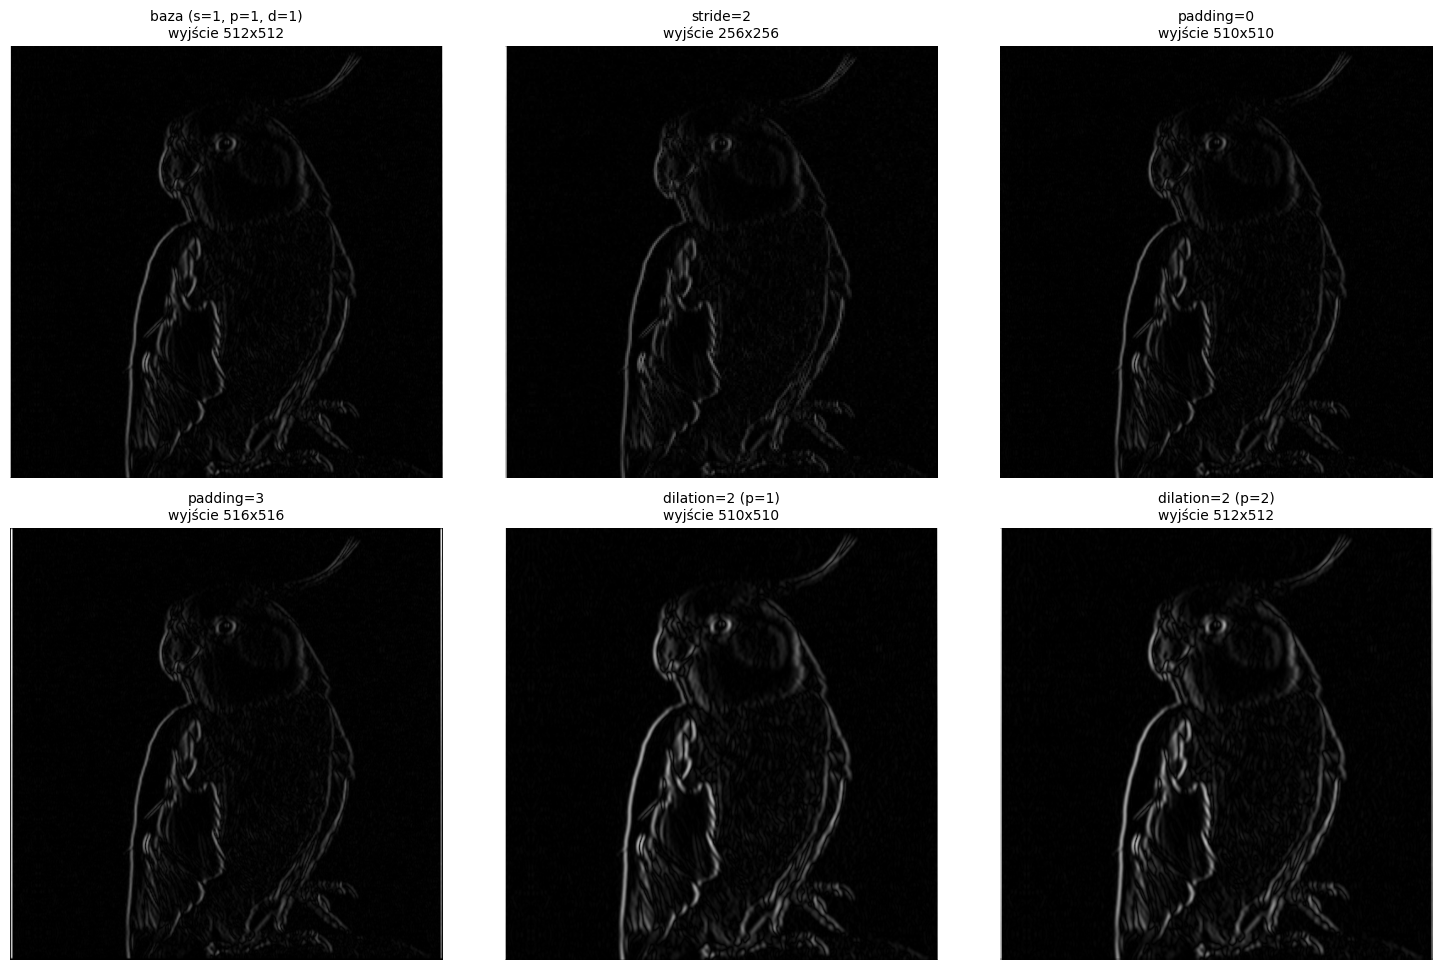

In [ ]:
variants = {
    "baza (s=1, p=1, d=1)": dict(stride=1, padding=1, dilation=1),
    "stride=2": dict(stride=2, padding=1, dilation=1),
    "padding=0": dict(stride=1, padding=0, dilation=1),
    "padding=3": dict(stride=1, padding=3, dilation=1),
    "dilation=2 (p=1)": dict(stride=1, padding=1, dilation=2),
    "dilation=2 (p=2)": dict(stride=1, padding=2, dilation=2),
}
outs, rows = {}, []
for name, kw in variants.items():
    out = F.conv2d(gray, sobel_x, **kw)
    outs[name] = out
    exp = (
        out_dim(H, 3, kw["stride"], kw["padding"], kw["dilation"]),
        out_dim(W, 3, kw["stride"], kw["padding"], kw["dilation"]),
    )
    rows.append(
        {
            "wariant": name,
            "stride": kw["stride"],
            "padding": kw["padding"],
            "dilation": kw["dilation"],
            "wejście": f"{H}x{W}",
            "wyjście": f"{out.shape[-2]}x{out.shape[-1]}",
            "zgodne ze wzorem": (
                "tak" if tuple(out.shape[-2:]) == exp else "NIE"
            ),
        }
    )
eff = pd.DataFrame(rows)
eff.to_csv(RES_DIR / "param_effects.csv", index=False)
display(eff)
print(eff.to_markdown(index=False))

vmax = max(o.abs().max().item() for o in outs.values())
fig, axes = plt.subplots(2, 3, figsize=(15, 9 * H / W + 0.8))
for ax, (name, out) in zip(axes.flat, outs.items()):
    ax.imshow(out[0, 0].abs(), cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(
        f"{name}\nwyjście {out.shape[-2]}x{out.shape[-1]}", fontsize=10
    )
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "param_effects.png", dpi=150)
plt.show()

Zera: min/max odpowiedzi -3.200000047683716 3.200000047683716
Replicate: min/max odpowiedzi 0.0 0.0


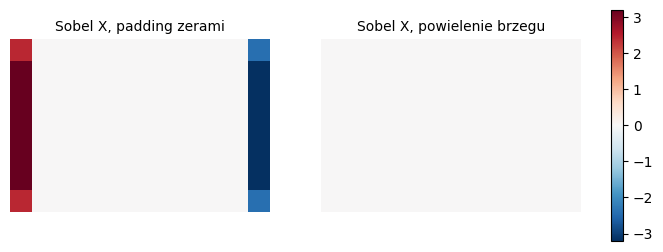

In [ ]:
# odpowiedź na brzegu: dopełnienie zerami vs powielenie brzegu
flat = torch.full((1, 1, 8, 12), 0.8)  # jasny, jednolity obraz
r_zero = F.conv2d(flat, sobel_x, padding=1)
r_rep = F.conv2d(F.pad(flat, (1, 1, 1, 1), mode="replicate"), sobel_x)
print("Zera: min/max odpowiedzi", r_zero.min().item(), r_zero.max().item())
print("Replicate: min/max odpowiedzi", r_rep.min().item(), r_rep.max().item())

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (title, r) in zip(
    axes, [("padding zerami", r_zero), ("powielenie brzegu", r_rep)]
):
    im = ax.imshow(r[0, 0], cmap="RdBu_r", vmin=-3.2, vmax=3.2)
    ax.set_title(f"Sobel X, {title}", fontsize=10)
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.03)
plt.savefig(FIG_DIR / "padding_modes.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Mapy cech pretrenowanego ResNet-18
Zdjęcie w skali szarości podajemy jako **trzy identyczne kanały**, z preprocessingiem modelu (zmniejszenie do 256, kadr środkowy 224×224, normalizacja). Mapy z `conv1` (po ReLU, jak we wstępie), z `layer1` i z `layer3` (głębsza warstwa). Pokazujemy 8 kanałów o największej średniej aktywności.

In [ ]:
from torchvision.models import ResNet18_Weights, resnet18

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()
x = preprocess(pil_rgb).unsqueeze(0).to(device)
print("Wejście sieci:", tuple(x.shape))

acts = {}


def save_to(key):
    def hook(module, inputs, output):
        acts[key] = output.detach().cpu()

    return hook


handles = [
    model.conv1.register_forward_hook(save_to("conv1")),
    model.layer1.register_forward_hook(save_to("layer1")),
    model.layer3.register_forward_hook(save_to("layer3")),
]
with torch.inference_mode():
    model(x)
for h_ in handles:
    h_.remove()

fmaps = {
    "conv1 (po ReLU)": torch.relu(acts["conv1"])[0],
    "layer1": acts["layer1"][0],
    "layer3": acts["layer3"][0],
}
for name, fm in fmaps.items():
    print(f"{name}: kształt {tuple(fm.shape)}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Wejście sieci: (1, 3, 224, 224)
conv1 (po ReLU): kształt (64, 112, 112)
layer1: kształt (64, 56, 56)
layer3: kształt (256, 14, 14)


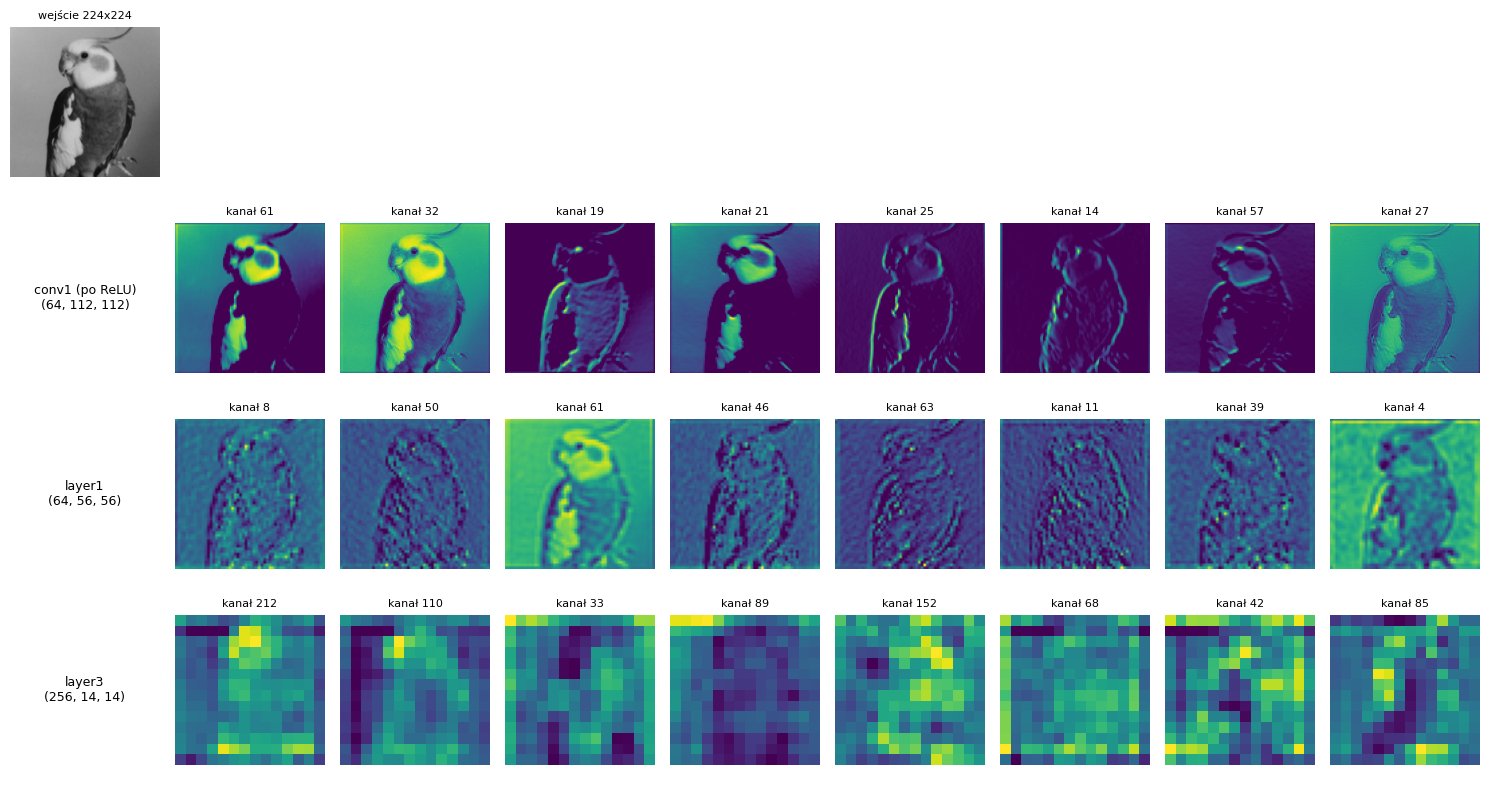

In [ ]:
mean_t = torch.tensor(preprocess.mean).view(3, 1, 1)
std_t = torch.tensor(preprocess.std).view(3, 1, 1)
inp = (x[0].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0)

n_show = 8
fig, axes = plt.subplots(4, n_show + 1, figsize=(15, 8))
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].imshow(inp)
axes[0, 0].set_title("wejście 224x224", fontsize=8)
for r, (name, fm) in enumerate(fmaps.items(), start=1):
    top_idx = fm.mean(dim=(1, 2)).topk(n_show).indices
    axes[r, 0].text(
        0.5,
        0.5,
        f"{name}\n{tuple(fm.shape)}",
        ha="center",
        va="center",
        fontsize=9,
    )
    for k, ch in enumerate(top_idx):
        axes[r, k + 1].imshow(fm[ch], cmap="viridis")
        axes[r, k + 1].set_title(f"kanał {int(ch)}", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "resnet_feature_maps.png", dpi=150)
plt.show()

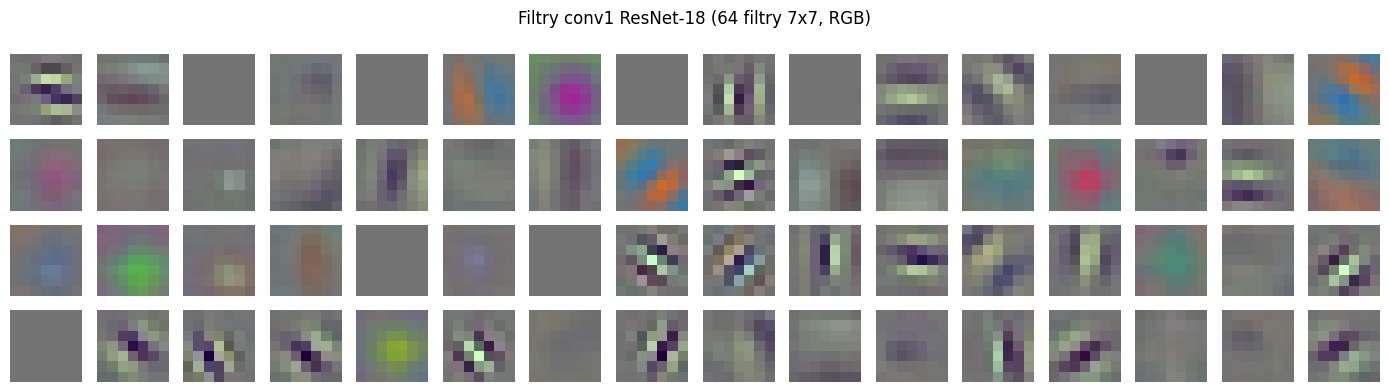

Kształt wag conv1: (64, 3, 7, 7)


In [ ]:
W1 = model.conv1.weight.detach().cpu()  # [64, 3, 7, 7]
W1n = (W1 - W1.min()) / (W1.max() - W1.min())
fig, axes = plt.subplots(4, 16, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(W1n[i].permute(1, 2, 0))
    ax.axis("off")
fig.suptitle("Filtry conv1 ResNet-18 (64 filtry 7x7, RGB)")
plt.tight_layout()
plt.savefig(FIG_DIR / "resnet_conv1_weights.png", dpi=150)
plt.show()
print("Kształt wag conv1:", tuple(W1.shape))

## 5. Porównanie filtrów rozmywających: Box 3×3, Box 5×5, Gaussian 5×5
`stride=1`, `dilation=1`, dopełnienie `p = k // 2` zachowuje rozmiar (`2p = d(k−1)`). Filtrujemy **całe zdjęcie**, a dopiero potem wycinamy ten sam fragment (bez efektów brzegu). Wspólna skala jasności 0–1.

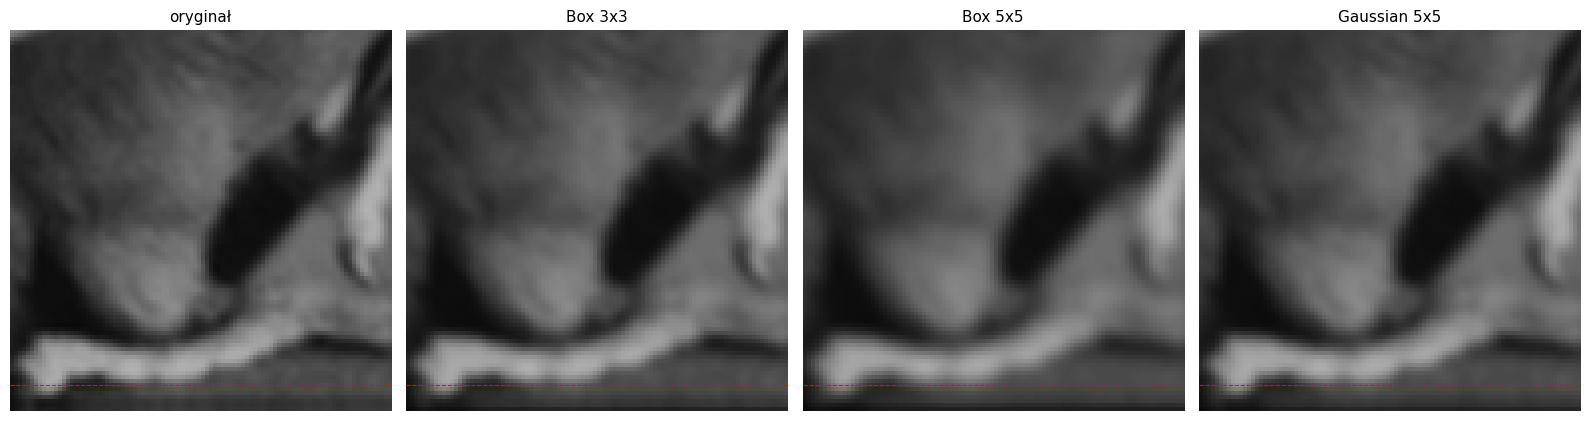

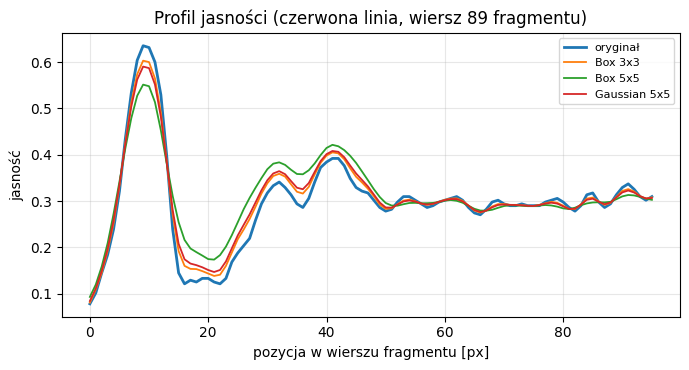

,wariant,średnia magnituda gradientu,maks. magnituda gradientu,odchylenie std jasności
0,oryginał,0.2209,1.3522,0.1431
1,Box 3x3,0.2056,1.1381,0.1401
2,Box 5x5,0.1859,0.8707,0.1346
3,Gaussian 5x5,0.1996,1.0773,0.1385


| wariant      |   średnia magnituda gradientu |   maks. magnituda gradientu |   odchylenie std jasności |
|:-------------|------------------------------:|----------------------------:|--------------------------:|
| oryginał     |                        0.2209 |                      1.3522 |                    0.1431 |
| Box 3x3      |                        0.2056 |                      1.1381 |                    0.1401 |
| Box 5x5      |                        0.1859 |                      0.8707 |                    0.1346 |
| Gaussian 5x5 |                        0.1996 |                      1.0773 |                    0.1385 |


In [ ]:
blur_defs = {
    "Box 3x3": (box3, 1),
    "Box 5x5": (box5, 2),
    "Gaussian 5x5": (gauss5, 2),
}
filtered = {"oryginał": gray}
for name, (ker, p) in blur_defs.items():
    out = F.conv2d(gray, ker, stride=1, padding=p, dilation=1)
    assert out.shape == gray.shape, f"{name}: rozmiar się zmienił"
    filtered[name] = out


def crop_of(t):
    return t[0, 0, top : top + size, left : left + size]


# wiersz fragmentu z najostrzejszą krawędzią poziomą (profil jasności)
c0 = crop_of(gray)
row = int((c0[:, 1:] - c0[:, :-1]).abs().max(dim=1).values.argmax())

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (name, t) in zip(axes, filtered.items()):
    ax.imshow(crop_of(t), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name, fontsize=11)
    ax.axhline(row, color="red", lw=0.8, ls="--")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "blur_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 3.8))
for name, t in filtered.items():
    plt.plot(crop_of(t)[row], label=name, lw=2 if name == "oryginał" else 1.3)
plt.xlabel("pozycja w wierszu fragmentu [px]")
plt.ylabel("jasność")
plt.title(f"Profil jasności (czerwona linia, wiersz {row} fragmentu)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "blur_profile.png", dpi=150)
plt.show()

rows = []
for name, t in filtered.items():
    grad = crop_of(sobel_magnitude(t))
    rows.append(
        {
            "wariant": name,
            "średnia magnituda gradientu": round(grad.mean().item(), 4),
            "maks. magnituda gradientu": round(grad.max().item(), 4),
            "odchylenie std jasności": round(crop_of(t).std().item(), 4),
        }
    )
blur_df = pd.DataFrame(rows)
blur_df.to_csv(RES_DIR / "blur_metrics.csv", index=False)
display(blur_df)
print(blur_df.to_markdown(index=False))

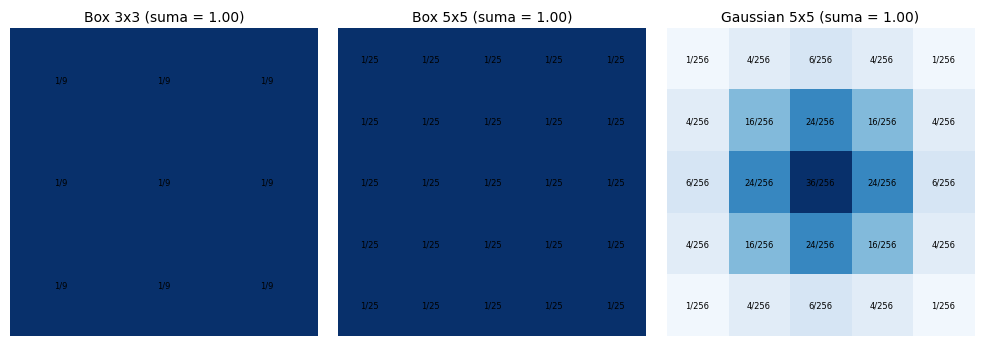

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (name, (ker, _)) in zip(axes, blur_defs.items()):
    w = ker[0, 0]
    ax.imshow(w, cmap="Blues", vmin=0, vmax=w.max().item())
    for i in range(w.shape[0]):
        for j in range(w.shape[1]):
            ax.text(
                j,
                i,
                (
                    f"{w[i, j] * 256:.0f}/256"
                    if name.startswith("G")
                    else f"1/{round(1 / w[0, 0].item())}"
                ),
                ha="center",
                va="center",
                fontsize=6,
            )
    ax.set_title(f"{name} (suma = {w.sum().item():.2f})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "blur_kernels.png", dpi=150)
plt.show()

## 6. Zakres dodatkowy
### 6.1 Własne jądro: krawędzie ukośne
Dwa jądra ukośne (typu Sobel obrócone o 45°). Najpierw test na syntetycznych liniach `\` i `/`, potem odpowiedź na zdjęciu.

,linia \,linia /
jądro A,0.3613,0.0068
jądro B,0.0068,0.3613


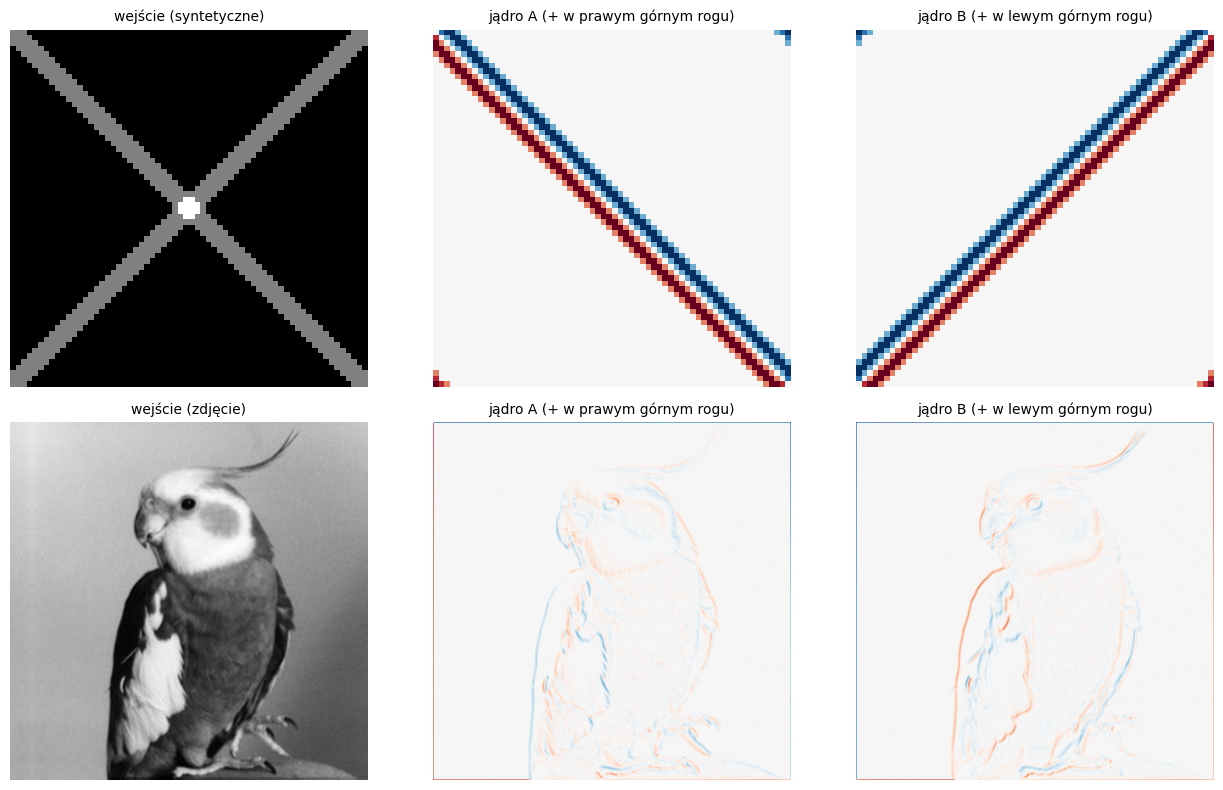

In [ ]:
diag_a = kernel([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]])
diag_b = kernel([[2, 1, 0], [1, 0, -1], [0, -1, -2]])

n_syn = 64
line_back = torch.zeros(1, 1, n_syn, n_syn)  # linia typu "\"
line_fwd = torch.zeros(1, 1, n_syn, n_syn)  # linia typu "/"
for i in range(n_syn):
    for off in range(-2, 3):
        if 0 <= i + off < n_syn:
            line_back[0, 0, i, i + off] = 1.0
        if 0 <= n_syn - 1 - i + off < n_syn:
            line_fwd[0, 0, i, n_syn - 1 - i + off] = 1.0

resp = {}
for pname, pat in [("linia \\", line_back), ("linia /", line_fwd)]:
    resp[pname] = {
        "jądro A": F.conv2d(pat, diag_a, padding=1).abs().mean().item(),
        "jądro B": F.conv2d(pat, diag_b, padding=1).abs().mean().item(),
    }
diag_df = pd.DataFrame(resp).round(4)
diag_df.to_csv(RES_DIR / "diagonal_kernels.csv")
display(diag_df)

ga = F.conv2d(gray, diag_a, padding=1)
gb = F.conv2d(gray, diag_b, padding=1)
vm = max(ga.abs().max().item(), gb.abs().max().item())
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax in axes.flat:
    ax.axis("off")
rows_ = [
    (
        "syntetyczne",
        line_back + line_fwd,
        F.conv2d(line_back + line_fwd, diag_a, padding=1),
        F.conv2d(line_back + line_fwd, diag_b, padding=1),
    ),
    ("zdjęcie", gray, ga, gb),
]
for r, (lbl, img, ra, rb) in enumerate(rows_):
    lim = (
        vm if lbl == "zdjęcie" else max(ra.abs().max(), rb.abs().max()).item()
    )
    axes[r, 0].imshow(img[0, 0], cmap="gray")
    axes[r, 0].set_title(f"wejście ({lbl})", fontsize=10)
    axes[r, 1].imshow(ra[0, 0], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[r, 1].set_title("jądro A (+ w prawym górnym rogu)", fontsize=10)
    axes[r, 2].imshow(rb[0, 0], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[r, 2].set_title("jądro B (+ w lewym górnym rogu)", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "diagonal_kernels.png", dpi=150)
plt.show()

### 6.2 Filtry pierwszej i głębszej warstwy
Po lewej 64 filtry `conv1` (RGB 7×7), po prawej 64 filtry `layer1[0].conv1` (3×3, uśrednione po 64 kanałach wejściowych, każdy znormalizowany osobno). Głębsze filtry działają na mapy cech, a nie na kolory, więc nie da się ich odczytać jak obrazów.

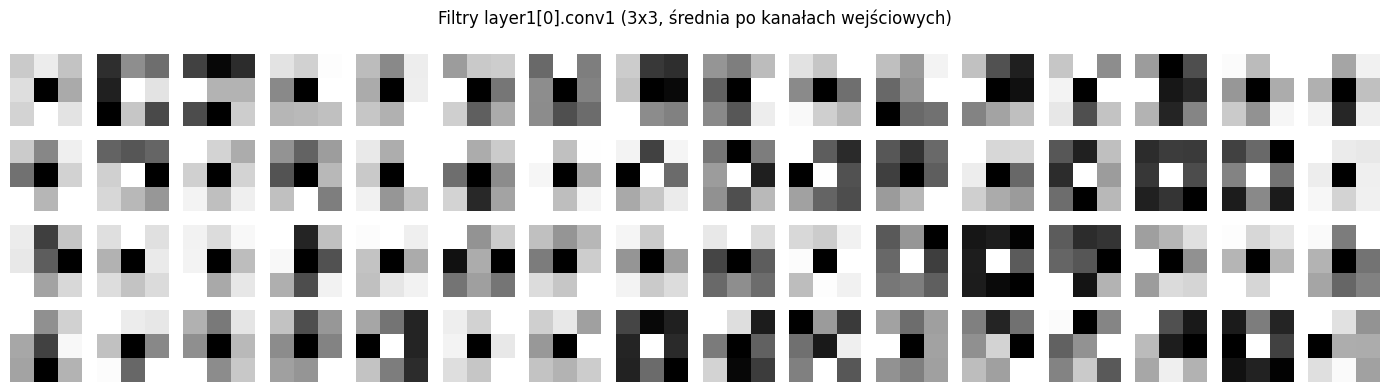

Kształt wag layer1[0].conv1: (64, 64, 3, 3)


In [ ]:
W2 = model.layer1[0].conv1.weight.detach().cpu()  # [64, 64, 3, 3]
W2m = W2.mean(dim=1)  # [64, 3, 3]
W2n = (W2m - W2m.amin(dim=(1, 2), keepdim=True)) / (
    W2m.amax(dim=(1, 2), keepdim=True)
    - W2m.amin(dim=(1, 2), keepdim=True)
    + 1e-8
)
fig, axes = plt.subplots(4, 16, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(W2n[i], cmap="gray")
    ax.axis("off")
fig.suptitle("Filtry layer1[0].conv1 (3x3, średnia po kanałach wejściowych)")
plt.tight_layout()
plt.savefig(FIG_DIR / "resnet_layer1_weights.png", dpi=150)
plt.show()
print("Kształt wag layer1[0].conv1:", tuple(W2.shape))

### 6.3 Liczba parametrów: `Conv2d` vs warstwa gęsta o tym samym wejściu i wyjściu
Conv2d: `C_out·C_in·k·k + C_out` (bez biasu: bez ostatniego składnika). Warstwa gęsta łączy każdy element wejścia z każdym elementem wyjścia: `in·out + out`, gdzie `in = C_in·H·W`, `out = C_out·H'·W'`.

In [ ]:
def conv_params(c_in, c_out, k, bias=True):
    return c_out * c_in * k * k + (c_out if bias else 0)


def dense_params(n_in, n_out):
    return n_in * n_out + n_out


specs = [
    (
        "Conv2d(3, 8, 3, p=1), 32x32",
        dict(c_in=3, c_out=8, k=3, p=1, s=1, hw=32, bias=True),
    ),
    (
        "Conv2d(64, 64, 3, p=1), 56x56 (layer1)",
        dict(c_in=64, c_out=64, k=3, p=1, s=1, hw=56, bias=True),
    ),
    (
        "Conv2d(3, 64, 7, s=2, p=3), 224x224 (conv1)",
        dict(c_in=3, c_out=64, k=7, p=3, s=2, hw=224, bias=False),
    ),
]
rows = []
for name, sp in specs:
    conv = nn.Conv2d(
        sp["c_in"],
        sp["c_out"],
        sp["k"],
        stride=sp["s"],
        padding=sp["p"],
        bias=sp["bias"],
    )
    real = sum(p.numel() for p in conv.parameters())
    assert real == conv_params(sp["c_in"], sp["c_out"], sp["k"], sp["bias"])
    ho = out_dim(sp["hw"], sp["k"], sp["s"], sp["p"])
    n_in = sp["c_in"] * sp["hw"] ** 2
    n_out = sp["c_out"] * ho**2
    dense = dense_params(n_in, n_out)
    rows.append(
        {
            "warstwa": name,
            "wejście": f"{sp['c_in']}x{sp['hw']}x{sp['hw']}",
            "wyjście": f"{sp['c_out']}x{ho}x{ho}",
            "parametry Conv2d": f"{real:,}",
            "parametry Linear": f"{dense:,}",
            "stosunek Linear / Conv2d": f"{dense / real:,.0f}",
        }
    )
par_df = pd.DataFrame(rows)
par_df.to_csv(RES_DIR / "params_conv_vs_dense.csv", index=False)
display(par_df)
print(par_df.to_markdown(index=False))

,warstwa,wejście,wyjście,parametry Conv2d,parametry Linear,stosunek Linear / Conv2d
0,"Conv2d(3, 8, 3, p=1), 32x32",3x32x32,8x32x32,224,"25,174,016","112,384"
1,"Conv2d(64, 64, 3, p=1), 56x56 (layer1)",64x56x56,64x56x56,"36,928","40,282,296,320","1,090,833"
2,"Conv2d(3, 64, 7, s=2, p=3), 224x224 (conv1)",3x224x224,64x112x112,"9,408","120,847,089,664","12,845,141"


| warstwa                                     | wejście   | wyjście    | parametry Conv2d   | parametry Linear   | stosunek Linear / Conv2d   |
|:--------------------------------------------|:----------|:-----------|:-------------------|:-------------------|:---------------------------|
| Conv2d(3, 8, 3, p=1), 32x32                 | 3x32x32   | 8x32x32    | 224                | 25,174,016         | 112,384                    |
| Conv2d(64, 64, 3, p=1), 56x56 (layer1)      | 64x56x56  | 64x56x56   | 36,928             | 40,282,296,320     | 1,090,833                  |
| Conv2d(3, 64, 7, s=2, p=3), 224x224 (conv1) | 3x224x224 | 64x112x112 | 9,408              | 120,847,089,664    | 12,845,141                 |


## 7. Pliki wynikowe
Do sprawozdania trafiają: `figures/*.png` oraz `results/*.csv`. Zdjęcie przed filtracją: `figures/photo_gray.png` i `figures/photo_and_crop.png`. Kod i sprawozdanie są osobnymi plikami.

In [ ]:
!zip -r lab5_wyniki.zip figures results
from google.colab import files
files.download("lab5_wyniki.zip")

  adding: figures/ (stored 0%)
  adding: figures/resnet_conv1_weights.png (deflated 23%)
  adding: figures/resnet_feature_maps.png (deflated 3%)
  adding: figures/blur_profile.png (deflated 5%)
  adding: figures/diagonal_kernels.png (deflated 2%)
  adding: figures/blur_kernels.png (deflated 20%)
  adding: figures/resnet_layer1_weights.png (deflated 35%)
  adding: figures/param_effects.png (deflated 2%)
  adding: figures/photo_and_crop.png (deflated 1%)
  adding: figures/photo_gray.png (deflated 0%)
  adding: figures/padding_modes.png (deflated 17%)
  adding: figures/blur_comparison.png (deflated 18%)
  adding: figures/hand_kernels.png (deflated 1%)
  adding: results/ (stored 0%)
  adding: results/output_dims.csv (deflated 51%)
  adding: results/param_effects.csv (deflated 49%)
  adding: results/diagonal_kernels.csv (deflated 32%)
  adding: results/kernel_sums.csv (deflated 33%)
  adding: results/params_conv_vs_dense.csv (deflated 39%)
  adding: results/blur_metrics.csv (deflated 27%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>